# 08. Interpreting tree ensembles: importance, partial dependence and SHAP

Three questions, three tools:
* **Which features matter overall?** Impurity importance (fast, biased) or permutation importance (honest, but splits credit between correlated features).
* **How does the prediction change with one feature?** Partial dependence (average) and ICE (one row at a time).
* **Why this prediction for this river?** SHAP values.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))
# a small, readable working set used throughout
F = ["up_stw_dwf_m3d_per_km2", "up_spill_hours_per_km2", "up_lc_urban", "up_lc_arable",
     "up_lc_improved_grass", "up_lc_seminatural", "up_area_km2", "local_n_private_sewage"]
d = t[t.phos_good.notna()].reset_index(drop=True)
X, y = d[F].to_numpy(float), d.phos_good.to_numpy(int)
groups = d.management_catchment.to_numpy()
print(X.shape, "share with good phosphate:", y.mean().round(3))

(3706, 8) share with good phosphate: 0.484


In [2]:
import lightgbm as lgb
m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30, verbose=-1).fit(X, y)

## Shapley values

Treat the features as players in a game whose payout is the model's prediction. Feature $j$'s Shapley value
is its average marginal contribution over all orders in which features could be added:
$$\phi_j = \sum_{S \subseteq N\setminus\{j\}} \frac{|S|!\,(|N|-|S|-1)!}{|N|!}\big[v(S\cup\{j\}) - v(S)\big].$$
They are the unique attribution that is *efficient* (contributions sum to prediction minus average),
*symmetric*, gives *zero to dummies* and is *additive*. In SHAP's interventional form, $v(S)$ is the mean
prediction when features in $S$ are fixed at this row's values and the others are drawn from a background sample.

With 8 features there are only $2^8 = 256$ subsets, so we can compute exact values by brute force and
compare them with the library.

In [3]:
from itertools import combinations
from math import factorial
f = lambda Z: m.predict(Z, raw_score=True)          # log-odds
bg = X[np.random.default_rng(0).choice(len(X), 100, replace=False)]
def v(row, S):
    Z = bg.copy(); Z[:, list(S)] = row[list(S)]; return f(Z).mean()
def shapley(row):
    n = len(row); phi = np.zeros(n)
    for j in range(n):
        others = [k for k in range(n) if k != j]
        for r in range(n):
            for S in combinations(others, r):
                w = factorial(len(S)) * factorial(n - len(S) - 1) / factorial(n)
                phi[j] += w * (v(row, S + (j,)) - v(row, S))
    return phi
i = int(np.argmax(d.up_stw_dwf_m3d_per_km2.values))  # the river with most effluent per km2
phi = shapley(X[i])
import shap
sv = shap.TreeExplainer(m, data=bg, feature_perturbation="interventional").shap_values(X[[i]])[0]
pd.DataFrame({"feature": F, "value": X[i], "brute force": phi, "TreeSHAP": sv}).round(4)

,feature,value,brute force,TreeSHAP
0,up_stw_dwf_m3d_per_km2,7257.0903,-0.4518,-0.4518
1,up_spill_hours_per_km2,93.7327,0.2286,0.2286
2,up_lc_urban,0.3979,-2.1188,-2.1188
3,up_lc_arable,0.0274,0.1899,0.1899
4,up_lc_improved_grass,0.1137,0.2756,0.2756
5,up_lc_seminatural,0.0947,0.2929,0.2929
6,up_area_km2,29.4333,0.2303,0.2303
7,local_n_private_sewage,0.0000,0.1069,0.1069


In [4]:
print("sum of contributions:", phi.sum().round(4), "= prediction - mean:", (f(X[[i]])[0] - f(bg).mean()).round(4))

sum of contributions: -1.2463 = prediction - mean: -1.2463


Brute force and TreeSHAP agree to four decimals. TreeSHAP gets the same answer in polynomial time by walking the trees
instead of enumerating subsets.

This river (the most effluent-heavy in England) is pushed down mainly by its 40% urban catchment. Note that
this *unconstrained* model gives its 94 spill hours per km² a **positive** contribution, which is physically
implausible. That is the kind of artefact the monotone constraints in notebook 07 remove.

## Correlated features share credit

In [5]:
X2 = np.c_[X, X[:, 0] * np.exp(np.random.default_rng(1).normal(0, 0.05, len(X)))]   # a near-copy of sewage flow
m2 = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30, verbose=-1).fit(X2, y)
s1 = np.abs(shap.TreeExplainer(m).shap_values(X)).mean(0)
s2 = np.abs(shap.TreeExplainer(m2).shap_values(X2)).mean(0)
print(f"mean |SHAP| for sewage flow: alone {s1[0]:.3f}; with a near-copy {s2[0]:.3f} + copy {s2[-1]:.3f} = {s2[0] + s2[-1]:.3f}")

mean |SHAP| for sewage flow: alone 0.559; with a near-copy 0.377 + copy 0.193 = 0.570


Add a near-duplicate and the credit is split between the two (0.38 + 0.19), while their sum (0.57) is about what the
original had alone (0.56). This is why the project reports **SHAP summed over pressure groups** (all spill features
together, all sewage-works features together) rather than ranking single correlated features.

## Partial dependence and ICE

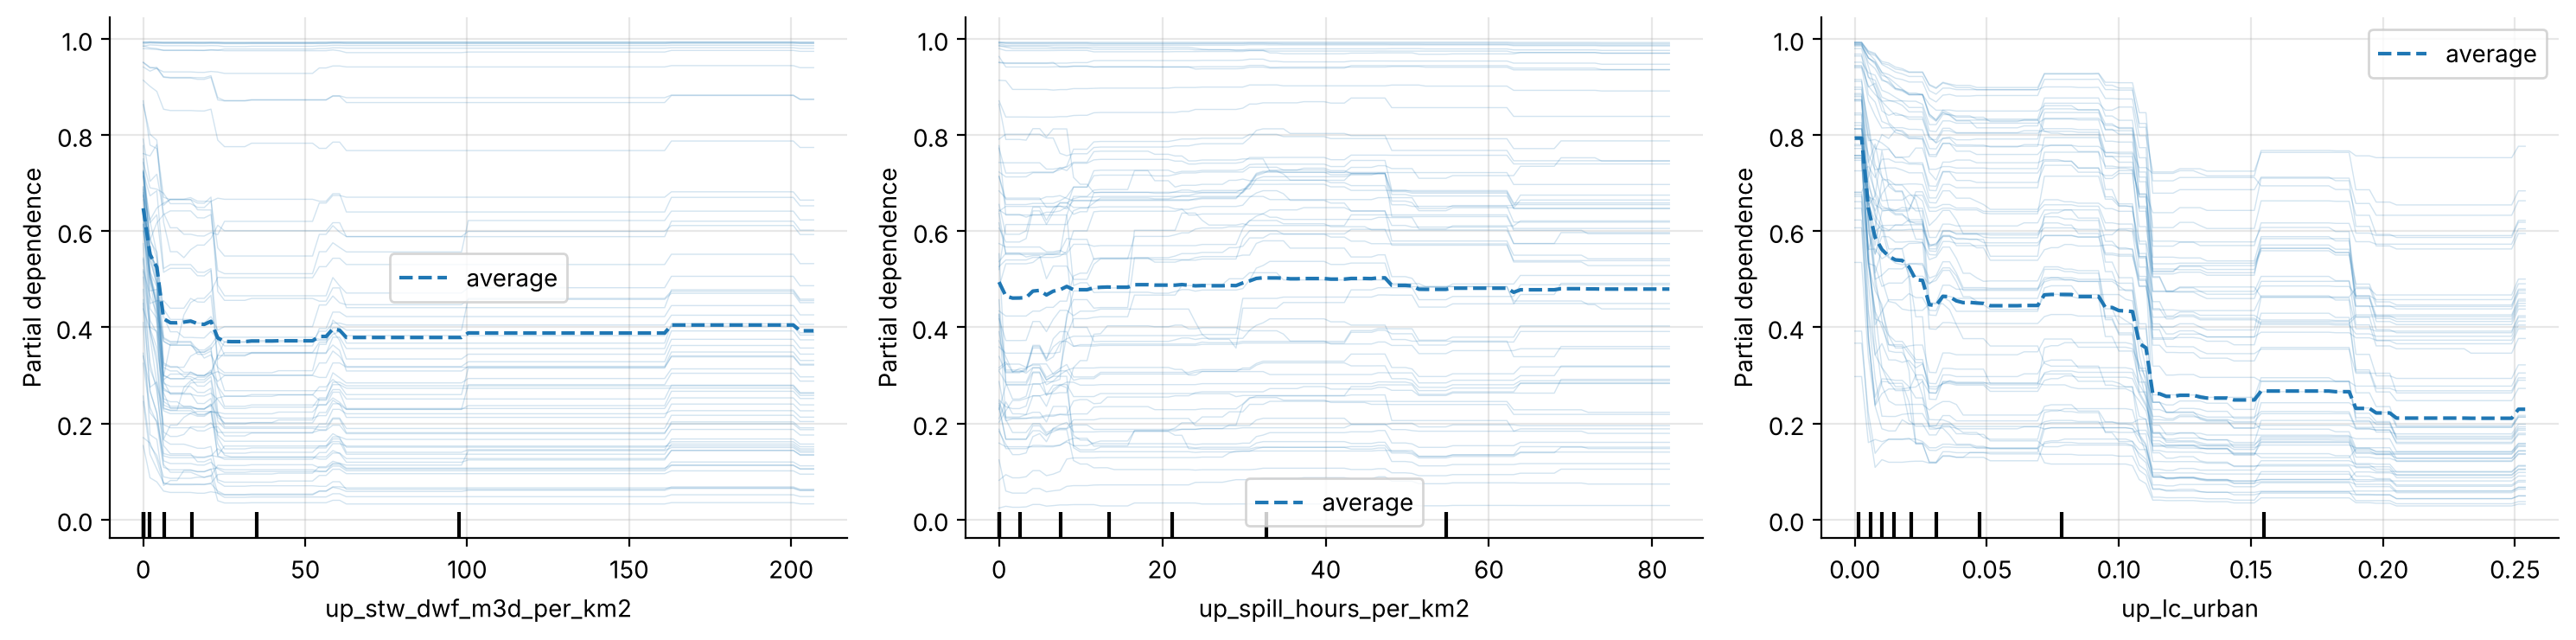

In [6]:
from sklearn.inspection import PartialDependenceDisplay
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
PartialDependenceDisplay.from_estimator(m, X, [0, 1, 2], feature_names=F, kind="both", subsample=60,
                                        ice_lines_kw={"alpha": 0.2}, ax=ax, random_state=0)
plt.tight_layout(); plt.show()

PDP averages over the data, including combinations that never occur (a mountain stream with the effluent
of a city). With strongly correlated features, prefer **accumulated local effects** (ALE) or SHAP dependence
plots, which only look at realistic neighbourhoods.